# Когорты, retention и LTV онлайн-ритейлера

**Вопрос бизнеса:** сколько приносит новый клиент за первые полгода, как часто он возвращается
и по каким признакам уже на первом заказе видно ценного клиента?

**Данные:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) (UCI) —
все строки накладных британского онлайн-магазина подарков и товаров для дома за 01.12.2009–09.12.2011.
Большая часть клиентов — небольшие оптовые покупатели. Суммы — в фунтах стерлингов.

In [1]:
import sys

sys.path.append("..")  # модули проекта: src/ и scripts/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import style
from src.clean import clean, load, to_orders
from src.cohorts import (
    LOOKBACK,
    add_first_order_tier,
    assign_cohorts,
    full_months,
    ltv_curve,
    retention_matrix,
    segment_summary,
)
from src.style import gbp, num, pct

style.apply()
pd.set_option("display.float_format", lambda x: num(x, 2))
DOCS = "../docs"

## 1. Очистка

Строка источника — позиция накладной. Перед анализом отбрасываю строки, которые не описывают
покупку товара конкретным клиентом. Накладные на `C` — возвраты: они уменьшают выручку,
но покупкой не считаются. Подробности проверок — в [`docs/data_quality.md`](../docs/data_quality.md).

In [2]:
raw = load("../data/raw/online_retail_II.csv")
lines, report = clean(raw)
orders = to_orders(lines)

no_customer = raw[raw["Customer ID"].isna()]
share_no_customer = (no_customer["Quantity"] * no_customer["Price"]).sum() / (
    raw["Quantity"] * raw["Price"]
).sum()

print(f"Строк в источнике: {num(len(raw))}")
for step, n in report.items():
    print(f"  отброшено — {step}: {num(n)}")
print(
    f"Осталось строк: {num(len(lines))}; накладных: {num(len(orders))}, из них возвратов: {num(orders.is_return.sum())}"
)
print(f"Клиентов: {num(orders.customer_id.nunique())}")
print(
    f"Доля выручки в строках без клиента: {num(share_no_customer * 100, 1)}% — по ним когорты не построить"
)

Строк в источнике: 1 067 371
  отброшено — без клиента: 243 007
  отброшено — полные дубли: 26 479
  отброшено — сервисные коды: 3 641
  отброшено — цена ≤ 0: 61
Осталось строк: 794 183; накладных: 43 877, из них возвратов: 7 283
Клиентов: 5 875
Доля выручки в строках без клиента: 13,7% — по ним когорты не построить


## 2. Кого считать новым клиентом

Данные начинаются в декабре 2009, но магазин работал и раньше. Оптовые клиенты заказывают редко,
поэтому давний клиент, который покупает раз в квартал, «впервые» появляется в данных
в феврале или марте 2010 и выглядит новым. Это видно по числу «новых» клиентов: в 2010 году
их в 2–3 раза больше, чем в 2011-м.

Поэтому первые 12 месяцев — **окно истории**: новым считаю клиента, который не покупал ни разу
за предыдущий год. Когорты — с декабря 2010 по ноябрь 2011.

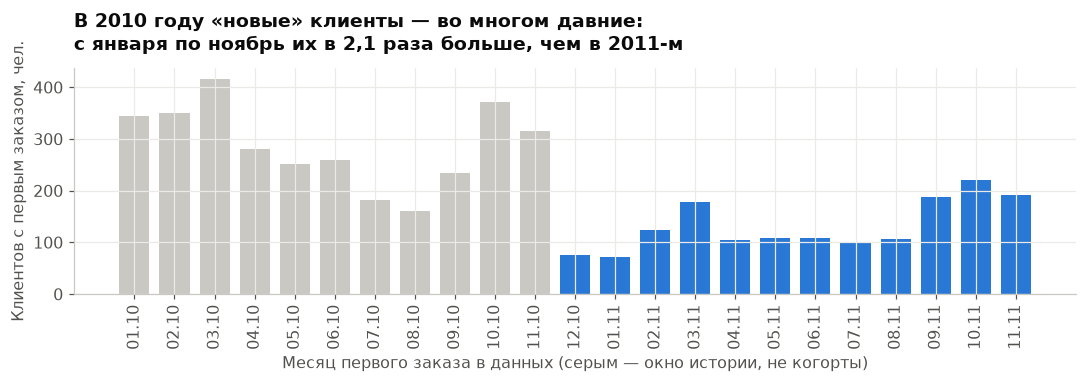

Новых клиентов в когортах: 1 577


In [3]:
months = full_months(raw["InvoiceDate"].min(), raw["InvoiceDate"].max())
df = assign_cohorts(orders)

first_seen = (
    df[~df["is_return"]]
    .groupby("customer_id")["month"]
    .min()
    .value_counts()
    .sort_index()
    .reindex(months[1:])
)
cohort_months = months[LOOKBACK:]

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = [style.ACCENT if m in cohort_months else style.CONTEXT for m in first_seen.index]
ax.bar(first_seen.index.strftime("%m.%y"), first_seen.values, color=colors, width=0.75)
ratio_2010 = first_seen[months[1:LOOKBACK]].sum() / first_seen[cohort_months[1:]].sum()
ax.set_title(
    f"В 2010 году «новые» клиенты — во многом давние:\nс января по ноябрь их в {num(ratio_2010, 1)} раза больше, чем в 2011-м"
)
ax.set_ylabel("Клиентов с первым заказом, чел.")
ax.set_xlabel("Месяц первого заказа в данных (серым — окно истории, не когорты)")
ax.tick_params(axis="x", labelrotation=90)
style.finish(fig, f"{DOCS}/new_customers.png")
plt.show()

new = df[df["cohort"].isin(cohort_months) & df["month"].isin(months)]
print(f"Новых клиентов в когортах: {num(new.customer_id.nunique())}")

## 3. Retention по месячным когортам

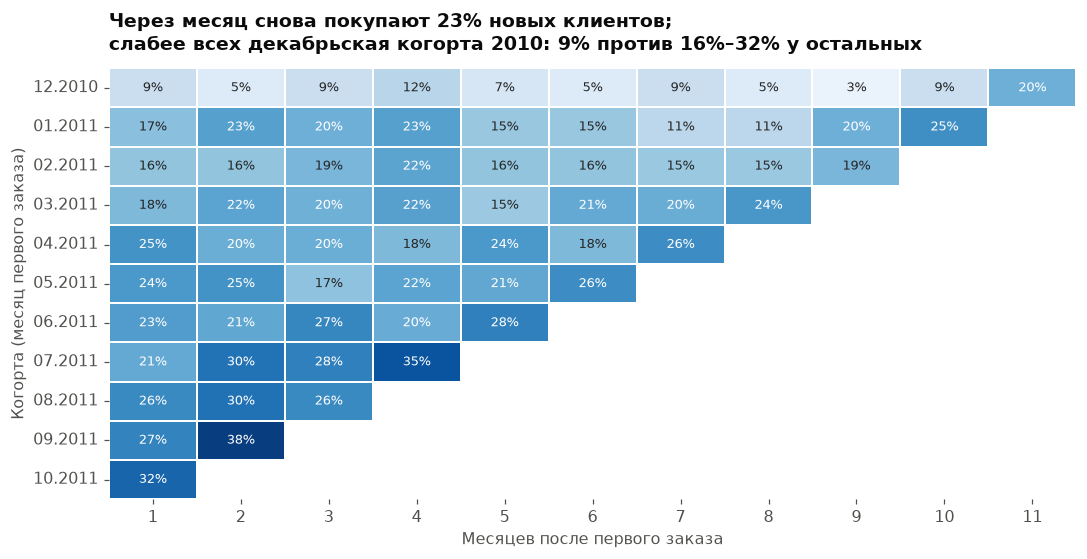

Retention 1-го месяца по когортам:
cohort
2010-12     9%
2011-01    17%
2011-02    16%
2011-03    18%
2011-04    25%
2011-05    24%
2011-06    23%
2011-07    21%
2011-08    26%
2011-09    27%
2011-10    32%
Freq: M


In [4]:
rm = retention_matrix(df, months)
heat = rm[rm["month_offset"] > 0].pivot(index="cohort", columns="month_offset", values="retention")
heat.index = heat.index.strftime("%m.%Y")

fig, ax = plt.subplots(figsize=(10, 5.2))
sns.heatmap(
    heat,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=0.4,
    cbar=False,
    linewidths=1,
    linecolor="white",
    annot_kws={"fontsize": 8.5},
    ax=ax,
)
r1 = rm.loc[rm.month_offset == 1, ["active", "cohort_size"]].sum()
first_month = rm[rm.month_offset == 1].set_index("cohort")["retention"]
dec, others = first_month[cohort_months[0]], first_month.drop(cohort_months[0])
ax.set_title(
    f"Через месяц снова покупают {r1.active / r1.cohort_size:.0%} новых клиентов;\n"
    f"слабее всех декабрьская когорта 2010: {dec:.0%} против {others.min():.0%}–{others.max():.0%} у остальных"
)
ax.set_xlabel("Месяцев после первого заказа")
ax.set_ylabel("Когорта (месяц первого заказа)")
ax.grid(False)
style.finish(fig, f"{DOCS}/retention_heatmap.png")
plt.show()

print("Retention 1-го месяца по когортам:")
print(first_month.map(lambda x: f"{x:.0%}").to_string())

Retention месяца N — доля когорты, сделавшая покупку через N месяцев после первого заказа.
Чтобы средние не искажались составом когорт (до 6-го месяца дожили не все), кривые ниже
считаются только по когортам, у которых есть полгода истории: декабрь 2010 — май 2011.

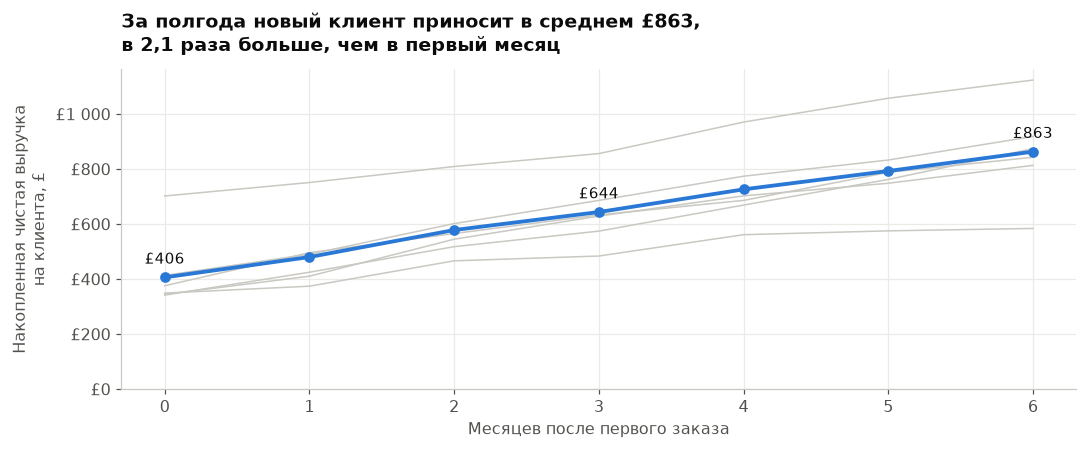

month_offset
0    100,0%
1     18,6%
2     19,2%
3     17,8%
4     20,4%
5     16,7%
6     17,9%
Клиентов в сопоставимых когортах: 663
LTV: первый месяц £406, полгода £863


In [5]:
HORIZON = 6
comparable = [c for c in cohort_months if (months[-1] - c).n >= HORIZON]
cmp_rm = rm[rm.cohort.isin(comparable) & (rm.month_offset <= HORIZON)]
curve = cmp_rm.groupby("month_offset")[["active", "cohort_size"]].sum()
curve["retention"] = curve["active"] / curve["cohort_size"]

ltv = ltv_curve(df, months)
cmp_ltv = ltv[ltv.cohort.isin(comparable) & (ltv.month_offset <= HORIZON)]
avg_ltv = (
    cmp_ltv.assign(total=cmp_ltv.cum_revenue_per_customer * cmp_ltv.cohort_size)
    .groupby("month_offset")[["total", "cohort_size"]]
    .sum()
)
avg_ltv = avg_ltv["total"] / avg_ltv["cohort_size"]

fig, ax = plt.subplots(figsize=(10, 4.2))
for _, g in cmp_ltv.groupby("cohort"):
    ax.plot(g.month_offset, g.cum_revenue_per_customer, color=style.CONTEXT, linewidth=1)
ax.plot(avg_ltv.index, avg_ltv.values, color=style.ACCENT, linewidth=2.5, marker="o")
for k in (0, 3, 6):
    ax.annotate(
        gbp(avg_ltv[k]),
        (k, avg_ltv[k]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        color=style.TEXT,
        fontsize=10,
    )
ax.set_title(
    f"За полгода новый клиент приносит в среднем {gbp(avg_ltv[HORIZON])},\n"
    f"в {num(avg_ltv[HORIZON] / avg_ltv[0], 1)} раза больше, чем в первый месяц"
)
ax.set_xlabel("Месяцев после первого заказа")
ax.set_ylabel("Накопленная чистая выручка\nна клиента, £")
ax.yaxis.set_major_formatter(style.GBP)
ax.set_xticks(range(HORIZON + 1))
ax.set_ylim(0, None)
style.finish(fig, f"{DOCS}/ltv.png")
plt.show()

print(curve["retention"].map(lambda x: f"{num(x * 100, 1)}%").to_string())
print(
    f"Клиентов в сопоставимых когортах: {num(cmp_rm.groupby('cohort').cohort_size.first().sum())}"
)
print(f"LTV: первый месяц {gbp(avg_ltv[0])}, полгода {gbp(avg_ltv[HORIZON])}")

## 4. Кто приносит выручку

In [6]:
six = new[new.cohort.isin(comparable) & (new.month_offset.between(0, HORIZON))]
purchases = six[~six.is_return].sort_values(["ts", "invoice"])
value = six.groupby("customer_id")["revenue"].sum()
first_order = purchases.groupby("customer_id")["revenue"].first().reindex(value.index).fillna(0)
repeat = purchases.groupby("customer_id")["month"].nunique().reindex(value.index).fillna(0) >= 2

print(f"Вернулись хотя бы раз за полгода: {pct(repeat.mean(), 0)} клиентов")
print(f"Их доля в выручке полугода: {pct(value[repeat].sum() / value.sum(), 0)}")
print(
    f"Выручка за полгода: вернувшиеся {gbp(value[repeat].mean())}, разовые {gbp(value[~repeat].mean())}"
)

Вернулись хотя бы раз за полгода: 52% клиентов
Их доля в выручке полугода: 82%
Выручка за полгода: вернувшиеся £1 377, разовые £316


**Сумма первого заказа как ранний сигнал.** Делю клиентов по сумме первого заказа относительно
медианы. Сам первый заказ входит в LTV, поэтому, чтобы не сравнивать очевидное, смотрю отдельно
на возвраты к покупкам и на выручку *после* первого заказа.

Медиана первого заказа: £288
Выручка после первого заказа: в 2,9 раза больше у крупного первого заказа


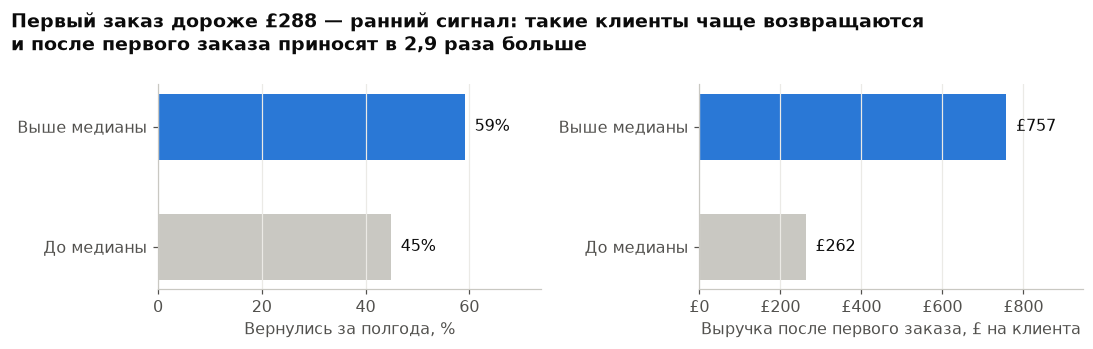

,Клиентов,Вернулись за полгода,"Первый заказ, £","Выручка после первого заказа, £","LTV 6 месяцев, £"
first_order,,,,,
Выше медианы,313,"0,59","601,33","757,02","1 358,34"
До медианы,350,"0,45","158,46","262,07","420,54"


In [7]:
tier = add_first_order_tier(new).groupby("customer_id")["first_order"].first().reindex(value.index)
median_first = (
    new[~new.is_return]
    .sort_values(["ts", "invoice"])
    .groupby("customer_id")["revenue"]
    .first()
    .median()
)
by_tier = pd.DataFrame(
    {
        "Клиентов": tier.value_counts(),
        "Вернулись за полгода": repeat.groupby(tier).mean(),
        "Первый заказ, £": first_order.groupby(tier).mean(),
        "Выручка после первого заказа, £": (value - first_order).groupby(tier).mean(),
        "LTV 6 месяцев, £": value.groupby(tier).mean(),
    }
).loc[["Выше медианы", "До медианы"]]
after = by_tier["Выручка после первого заказа, £"]
after_ratio = after["Выше медианы"] / after["До медианы"]
print(f"Медиана первого заказа: {gbp(median_first)}")
print(
    f"Выручка после первого заказа: в {num(after_ratio, 1)} раза больше у крупного первого заказа"
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
panels = [
    (
        axes[0],
        by_tier["Вернулись за полгода"] * 100,
        "Вернулись за полгода, %",
        lambda v: f"  {num(v, 0)}%",
    ),
    (axes[1], after, "Выручка после первого заказа, £ на клиента", lambda v: "  " + gbp(v)),
]
for ax, series, xlabel, label in panels:
    t = series.iloc[::-1]
    ax.barh(t.index, t.values, color=[style.CONTEXT, style.ACCENT], height=0.55)
    for y, v in enumerate(t.values):
        ax.text(v, y, label(v), va="center", color=style.TEXT)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, t.max() * 1.25)
    ax.grid(axis="y", visible=False)
axes[1].xaxis.set_major_formatter(style.GBP)
fig.suptitle(
    f"Первый заказ дороже {gbp(median_first)} — ранний сигнал: такие клиенты чаще возвращаются\n"
    f"и после первого заказа приносят в {num(after_ratio, 1)} раза больше",
    x=0.01,
    ha="left",
    fontsize=12.5,
    fontweight="bold",
)
style.finish(fig, f"{DOCS}/segments.png")
plt.show()
by_tier

**Иностранные клиенты.** Средний заказ у них выше, но клиентов мало, а выручка оптовиков
распределена с тяжёлым хвостом — проверяю разницу LTV бутстрапом.

In [8]:
region = six.groupby("customer_id")["region"].first().reindex(value.index)
rng = np.random.default_rng(42)
uk, other = value[region == "Великобритания"].values, value[region == "Другие страны"].values
boot = [rng.choice(other, other.size).mean() - rng.choice(uk, uk.size).mean() for _ in range(2000)]
low, high = np.percentile(boot, [2.5, 97.5])
by_region = segment_summary(add_first_order_tier(new), months, by="region", ltv_month=HORIZON)
print(
    f"LTV 6 месяцев: другие страны {gbp(other.mean())} (n = {other.size}), "
    f"Великобритания {gbp(uk.mean())} (n = {uk.size})"
)
print(f"Разница: {gbp(other.mean() - uk.mean())}, 95% бутстрап-ДИ [{gbp(low)}; {gbp(high)}]")
by_region

LTV 6 месяцев: другие страны £1 144 (n = 78), Великобритания £826 (n = 585)
Разница: £318, 95% бутстрап-ДИ [−£36; £768]


,segment,customers,retention,avg_order,ltv,after_first
0,Великобритания,1393,"0,21","358,43","825,83","476,58"
1,Другие страны,184,"0,20","490,83","1 144,08","639,42"


## Выводы и рекомендации

1. **Новый клиент за полгода приносит около £863**, из них £406 — в первый месяц: больше половины
   ценности приходит позже, поэтому удержание стоит не меньше, чем привлечение.
2. **Возвращается каждый второй.** 52% новых клиентов покупают снова в течение полугода, и на них
   приходится 82% выручки полугода. Retention по месяцам ровный, 17–20%: оставшиеся клиенты
   заказывают регулярно. Слабее всех декабрьская когорта 2010 года: через месяц вернулись 9%
   против 16–32% у остальных когорт — похоже на разовых предновогодних покупателей.
3. **Сумма первого заказа — ранний сигнал ценности.** Клиенты с первым заказом выше медианы (£288)
   чаще возвращаются (59% против 45%) и после первого заказа приносят в 2,9 раза больше.
   *Рекомендация:* после крупного первого заказа подключать персонального менеджера или условия
   для постоянных клиентов, маленькие первые заказы стимулировать к повтору (скидка на второй заказ).
4. **Иностранные клиенты — гипотеза, а не вывод.** Средний заказ у них выше, LTV за полгода
   £1 144 против £826, но клиентов всего 78 и интервал разницы включает ноль. Проверять на следующем
   периоде, прежде чем вкладываться в этот сегмент.

**Ограничения.** 13,7% выручки — без идентификатора клиента. LTV — выручка за вычетом возвратов,
без маржи и затрат на привлечение. Окно истории в 12 месяцев отсекает давних клиентов, но клиент,
не покупавший больше года, будет посчитан новым.

In [9]:
from scripts.export import export_all

for path in export_all(df, months, "../data/datalens"):
    print(path.name)

new_customers.csv
retention.csv
ltv.csv
segments.csv
